In [15]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals, bh_projections

In [16]:
import importlib
importlib.reload(transforms)

L = 123
sigma = 2

f = utils.generate_centered_gaussian(L, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 10, 0)     # move centered blob down
f_2 = transforms.translate_3d(f, 0, -15, -20)  # move blob far left and up
f_3 = transforms.translate_3d(f, 10, 0, 10)    # move blob back and right
F = f_1 + f_2 + f_3
F = signals.Signal(F, d=3).preprocess_signals()[0]

Pf = transforms.Transform(F, d=3).radon_transform()[0]





In [17]:


omega = np.deg2rad(20)
theta = np.deg2rad(157)
phi = np.deg2rad(53)

# G = transforms.rotate_voxel_zyz(F, -phi, -theta, -omega, order=1)
G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)


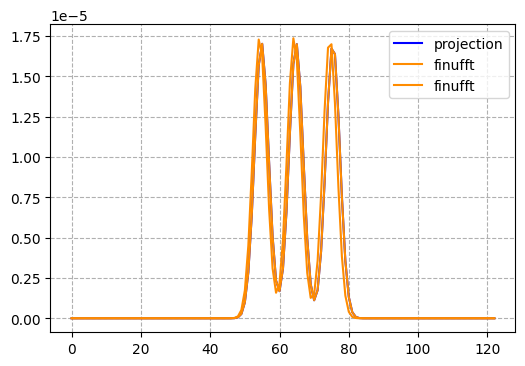

 theta gt:  157.0
theta idx:  156.3934426229508
   phi gt:  53.0
  phi idx:  52.68292682926829


In [19]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))
Pg = transforms.Transform(G, d=3).radon_transform()[0]

plt.figure(figsize=(6,4))

plt.plot(np.sum(G, axis=(0,1))*(2-2/L)**2/L**2, color='blue', label='projection')

plt.plot(Pf[phi_idx, :, theta_idx], color='darkorange', label='finufft')
plt.plot(Pg[0, :, 0], color='darkorange', label='finufft')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])

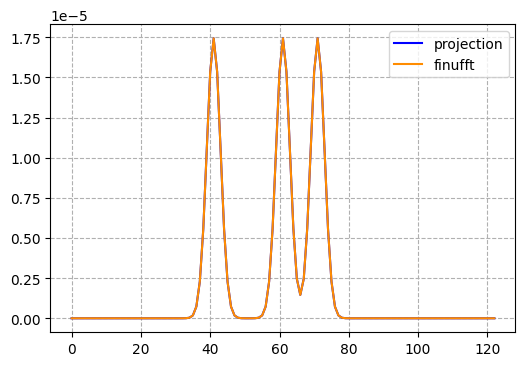

 theta gt:  157.0
theta idx:  156.3934426229508
   phi gt:  53.0
  phi idx:  52.68292682926829


In [20]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

plt.figure(figsize=(6,4))

plt.plot(np.sum(F, axis=(0,1))*(2-2/L)**2/L**2, color='blue', label='projection')

plt.plot(Pf[0, :, 0], color='darkorange', label='finufft')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])

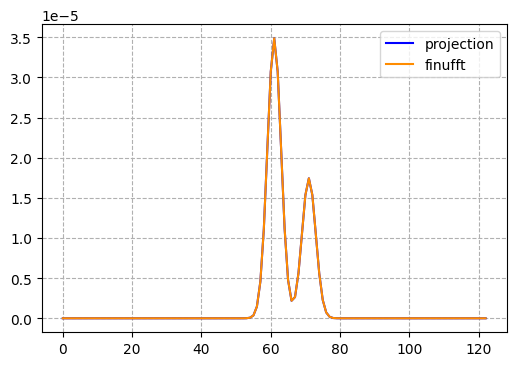

 theta gt:  157.0
theta idx:  156.3934426229508
   phi gt:  53.0
  phi idx:  52.68292682926829


In [21]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

plt.figure(figsize=(6,4))

# plt.plot(np.sum(F, axis=(0,2)), color='blue', label='projection')
# plt.plot(Pf[0, :, len(thetas)//2], color='darkorange', label='finufft')

plt.plot(np.sum(F, axis=(1,2))*(2-2/L)**2/L**2, color='blue', label='projection')
plt.plot(Pf[0, :, len(thetas)//2], color='darkorange', label='finufft')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])

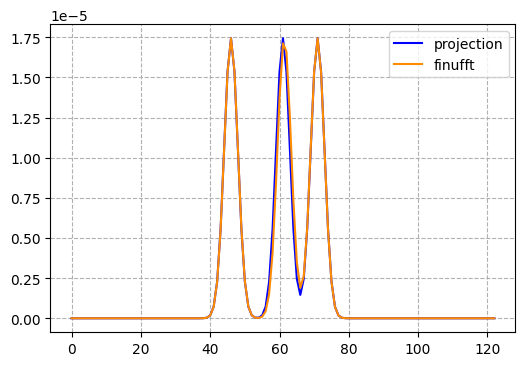

 theta gt:  157.0
theta idx:  156.3934426229508
   phi gt:  53.0
  phi idx:  52.68292682926829


In [22]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

plt.figure(figsize=(6,4))

# plt.plot(np.sum(F, axis=(1,2)), color='blue', label='projection')
# plt.plot(Pf[len(phis)//4+1, :, len(thetas)//2], color='darkorange', label='finufft')

plt.plot(np.sum(F, axis=(0,2))*(2-2/L)**2/L**2, color='blue', label='projection')
plt.plot(Pf[len(phis)//4, :, len(thetas)//2], color='darkorange', label='finufft')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])